# Baseline Predictive Modeling

## Objective

The objective of this notebook is to establish an initial predictive performance baseline for the credit default prediction task.

Several machine learning algorithms will be trained using the original dataset, without applying feature engineering, resampling techniques, feature selection, or hyperparameter optimization.

The results will help us understand the predictive potential of the available variables, compare different modeling approaches, and identify opportunities for future improvements.

All models will be evaluated using the same stratified train-test split.

In [24]:
#Importar librerias
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [7]:
# Directorio raíz del proyecto
PROJECT_ROOT = Path.cwd().parent

# Ruta del archivo
DATA_PATH = PROJECT_ROOT / "Data" / "default of credit card clients.xls"

# Cargar dataset
df = pd.read_excel(DATA_PATH, header=1)

print("Dataset :", df.shape)

Dataset : (30000, 25)


In [8]:
# Define target variable
TARGET = "default payment next month"

# Separate features and target
X = df.drop(columns=[TARGET, "ID"])
y = df[TARGET]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (30000, 23)
Target shape: (30000,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nDefault proportion:")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Training set: (24000, 23)
Test set: (6000, 23)

Default proportion:
Training: 22.12 %
Test: 22.12 %


In [10]:
## entrenamiento de modelos

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Dummy Classifier": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(random_state=42),

    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [11]:
trained_models = {}

for name, model in models.items():

    print(f"Training: {name}")

    model.fit(X_train, y_train)

    trained_models[name] = model

print("\nAll models trained successfully.")

Training: Dummy Classifier
Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting

All models trained successfully.


In [12]:
for name, model in trained_models.items():
    print(f"{name}: {type(model).__name__}")

Dummy Classifier: DummyClassifier
Logistic Regression: Pipeline
Decision Tree: DecisionTreeClassifier
Random Forest: RandomForestClassifier
Gradient Boosting: GradientBoostingClassifier


In [13]:
#Importar metricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [14]:
#Evaluar resultados
results = []

for name, model in trained_models.items():

    # Predict classes
    y_pred = model.predict(X_test)

    # Predict probabilities
    y_proba = model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Average Precision": average_precision_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Gradient Boosting,0.8183,0.6634,0.3625,0.4688,0.7784,0.5538
1,Random Forest,0.8120,0.6325,0.3580,0.4572,0.7506,0.5317
2,Logistic Regression,0.8077,0.6868,0.2396,0.3553,0.7076,0.4939
3,Decision Tree,0.7145,0.3694,0.4115,0.3893,0.6075,0.2827
4,Dummy Classifier,0.7788,0.0000,0.0000,0.0000,0.5000,0.2212


NameError: name 'FIGURES_PATH' is not defined

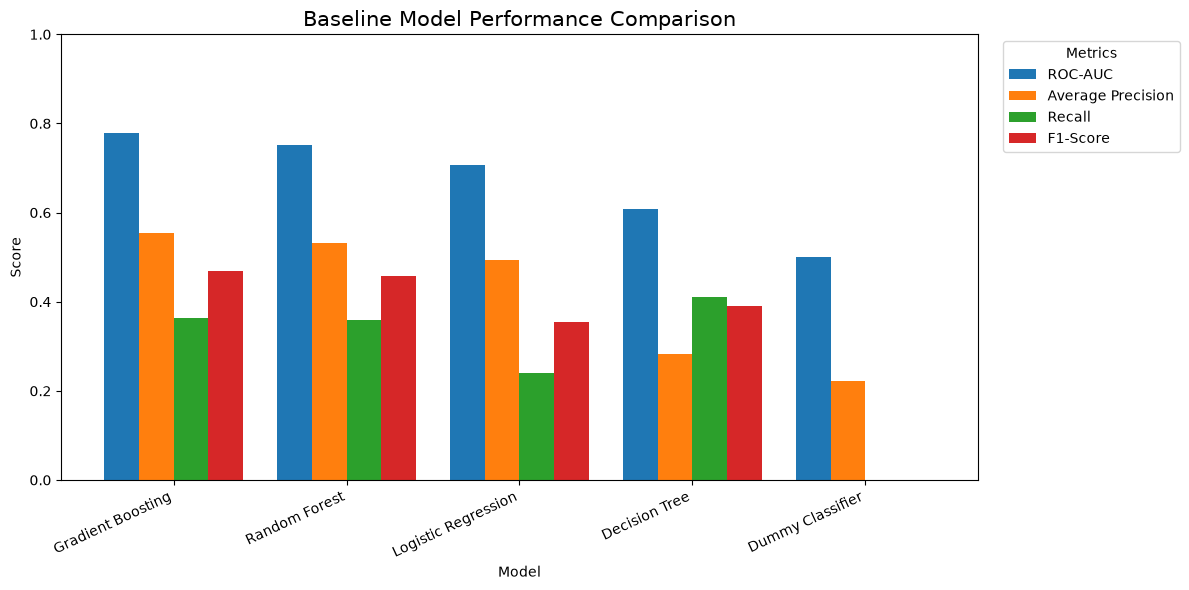

In [15]:
metrics_to_plot = [
    "ROC-AUC",
    "Average Precision",
    "Recall",
    "F1-Score"
]

plot_results = results_df.set_index("Model")[metrics_to_plot]

ax = plot_results.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Baseline Model Performance Comparison", fontsize=15)
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.savefig(
    FIGURES_PATH / "baseline_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

NameError: name 'FIGURES_PATH' is not defined

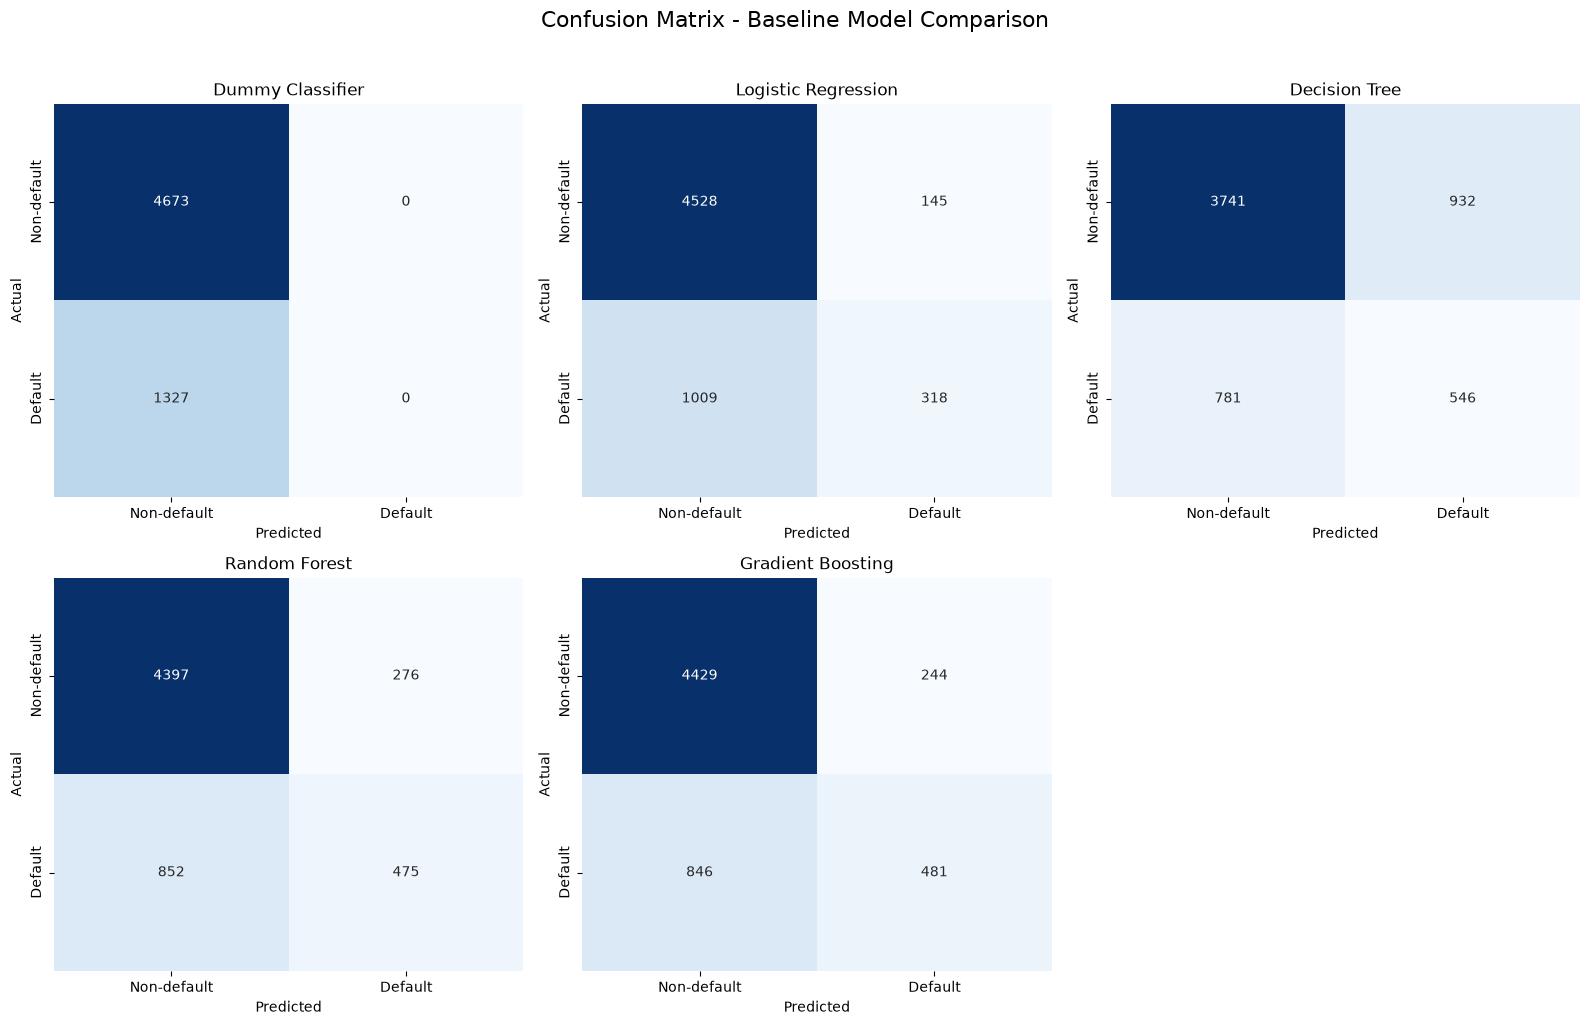

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Non-default", "Default"],
        yticklabels=["Non-default", "Default"],
        ax=axes[i]
    )

    axes[i].set_title(name, fontsize=12)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.suptitle(
    "Confusion Matrix - Baseline Model Comparison",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "baseline_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
from sklearn.metrics import confusion_matrix

confusion_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    confusion_results.append({
        "Model": name,
        "True Negatives (TN)": tn,
        "False Positives (FP)": fp,
        "False Negatives (FN)": fn,
        "True Positives (TP)": tp
    })

confusion_df = pd.DataFrame(confusion_results)

confusion_df

,Model,True Negatives (TN),False Positives (FP),False Negatives (FN),True Positives (TP)
0,Dummy Classifier,4673,0,1327,0
1,Logistic Regression,4528,145,1009,318
2,Decision Tree,3741,932,781,546
3,Random Forest,4397,276,852,475
4,Gradient Boosting,4429,244,846,481


## Confusion Matrix Analysis

The confusion matrix analysis revealed differences in the classification behavior of the baseline models.

- **Gradient Boosting** achieved the best overall performance, with 481 correctly identified default cases and 244 false positives.
- **Random Forest** showed similar behavior, identifying 475 default cases with 276 false positives.
- **Decision Tree** achieved the highest recall, identifying 546 default cases, but generated 932 false positives.
- **Logistic Regression** generated fewer false positives (145), but failed to identify a large proportion of actual default cases.
- **Dummy Classifier** failed to identify any default cases, highlighting the limitations of accuracy as a standalone evaluation metric.

Overall, Gradient Boosting and Random Forest appear to offer the most promising balance among the baseline models.

Further analysis is required before selecting a final model.

In [19]:
#Importancia de variables
tree_models = {
    "Decision Tree": trained_models["Decision Tree"],
    "Random Forest": trained_models["Random Forest"],
    "Gradient Boosting": trained_models["Gradient Boosting"]
}

feature_importance_results = []

for model_name, model in tree_models.items():

    importances = model.feature_importances_

    for feature, importance in zip(X_train.columns, importances):

        feature_importance_results.append({
            "Model": model_name,
            "Feature": feature,
            "Importance": importance
        })

feature_importance_df = pd.DataFrame(feature_importance_results)

feature_importance_df.head()

,Model,Feature,Importance
0,Decision Tree,LIMIT_BAL,0.061455
1,Decision Tree,SEX,0.013006
2,Decision Tree,EDUCATION,0.016673
3,Decision Tree,MARRIAGE,0.013881
4,Decision Tree,AGE,0.076403


In [20]:
importance_pivot = feature_importance_df.pivot(
    index="Feature",
    columns="Model",
    values="Importance"
)

importance_pivot["Mean Importance"] = importance_pivot.mean(axis=1)

importance_pivot = importance_pivot.sort_values(
    by="Mean Importance",
    ascending=False
)

importance_pivot.round(4)

Model,Decision Tree,Gradient Boosting,Random Forest,Mean Importance
Feature,,,,
PAY_0,0.1607,0.6347,0.1017,0.2990
BILL_AMT1,0.0701,0.0371,0.0593,0.0555
PAY_2,0.0373,0.0765,0.0428,0.0522
AGE,0.0764,0.0091,0.0665,0.0506
LIMIT_BAL,0.0615,0.0279,0.0612,0.0502
PAY_AMT3,0.0572,0.0241,0.0461,0.0425
PAY_AMT2,0.0500,0.0207,0.0481,0.0396
PAY_AMT1,0.0499,0.0170,0.0509,0.0392
PAY_AMT6,0.0516,0.0064,0.0463,0.0348


### Feature Importance – Baseline Models

The feature importance analysis reveals that historical payment behavior is the strongest predictor of credit default across the three tree-based models.

`PAY_0`, representing the most recent payment status, ranks first in all models, with particularly high importance in Gradient Boosting (0.6347). `PAY_2` also shows consistent predictive relevance.

Billing amounts and previous payment amounts contribute additional information, while demographic variables such as `SEX`, `MARRIAGE`, and `EDUCATION` show comparatively lower importance.

Some differences are observed across algorithms. Gradient Boosting concentrates a substantial proportion of its importance on `PAY_0`, whereas Random Forest distributes importance more evenly across financial and payment-related variables.

These results are based on impurity-based feature importance and should be interpreted as model-specific measures of predictive contribution, not as evidence of causality.

**Key finding:** Payment history appears to be the dominant source of predictive information in the baseline models.

In [21]:
logistic_model = trained_models["Logistic Regression"]

coefficients = logistic_model.named_steps["model"].coef_[0]

logistic_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients
})

logistic_importance_df["Abs Coefficient"] = (
    logistic_importance_df["Coefficient"].abs()
)

logistic_importance_df = logistic_importance_df.sort_values(
    by="Abs Coefficient",
    ascending=False
)

logistic_importance_df.round(4)

,Feature,Coefficient,Abs Coefficient
5,PAY_0,0.6610,0.6610
11,BILL_AMT1,-0.3162,0.3162
17,PAY_AMT1,-0.2022,0.2022
18,PAY_AMT2,-0.1796,0.1796
0,LIMIT_BAL,-0.1332,0.1332
2,EDUCATION,-0.0973,0.0973
7,PAY_3,0.0972,0.0972
6,PAY_2,0.0931,0.0931
12,BILL_AMT2,0.0929,0.0929
4,AGE,0.0738,0.0738


In [22]:
import shap

# Seleccionar nuestro mejor modelo
best_model = trained_models["Gradient Boosting"]

# Crear el explicador SHAP
explainer = shap.TreeExplainer(best_model)

# Calcular valores SHAP sobre el conjunto de prueba
shap_values = explainer.shap_values(X_test)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (6000, 23)


In [25]:
shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance.round(4)

,Feature,Mean SHAP
0,PAY_0,0.4417
1,LIMIT_BAL,0.1819
2,BILL_AMT1,0.1191
3,PAY_2,0.0929
4,PAY_AMT3,0.0922
5,PAY_AMT2,0.0859
6,PAY_AMT1,0.0800
7,PAY_3,0.0773
8,PAY_AMT6,0.0571
9,PAY_6,0.0539


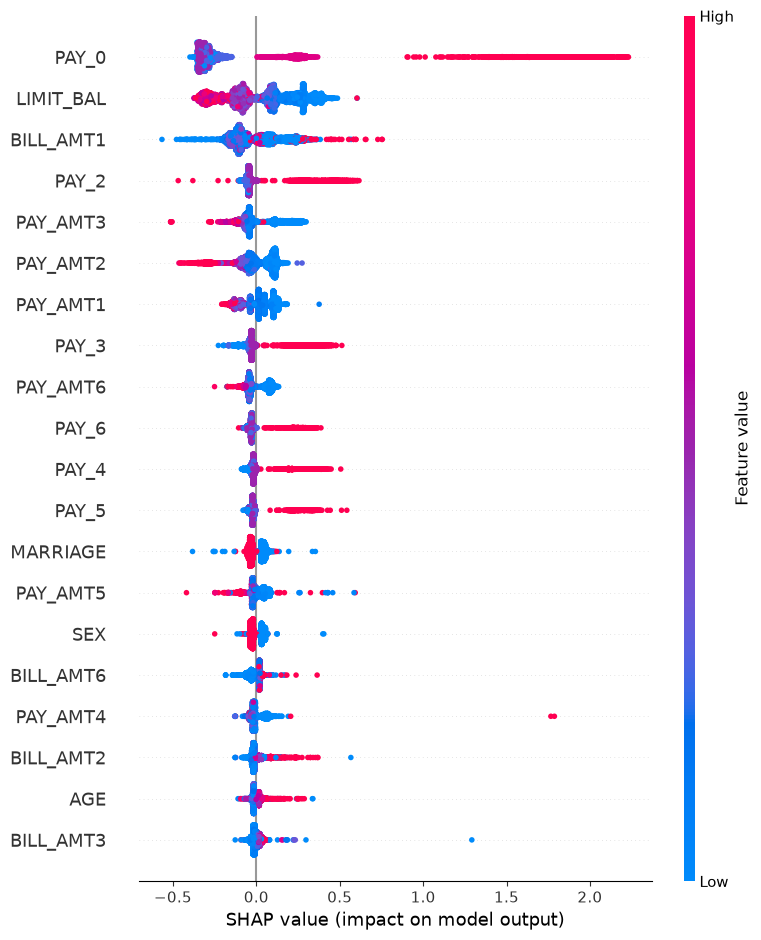

In [26]:
shap.summary_plot(
    shap_values,
    X_test,
    max_display=20
)

In [27]:
shap_direction = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean SHAP": shap_values.mean(axis=0),
    "Mean Absolute SHAP": np.abs(shap_values).mean(axis=0),
    "Positive SHAP %": (shap_values > 0).mean(axis=0) * 100,
    "Negative SHAP %": (shap_values < 0).mean(axis=0) * 100
})

shap_direction = shap_direction.sort_values(
    by="Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

shap_direction.round(4)

,Feature,Mean SHAP,Mean Absolute SHAP,Positive SHAP %,Negative SHAP %
0,PAY_0,-0.0300,0.4417,22.0667,77.9333
1,LIMIT_BAL,0.0212,0.1819,51.1667,48.8333
2,BILL_AMT1,-0.0073,0.1191,43.1000,56.9000
3,PAY_2,0.0133,0.0929,14.8833,85.1167
4,PAY_AMT3,-0.0012,0.0922,28.0333,71.9667
5,PAY_AMT2,-0.0037,0.0859,44.8167,55.1833
6,PAY_AMT1,0.0054,0.0800,59.7000,40.3000
7,PAY_3,0.0022,0.0773,14.2833,85.7167
8,PAY_AMT6,0.0017,0.0571,38.2167,61.7833
9,PAY_6,-0.0047,0.0539,10.1667,89.8333


In [28]:
shap_group_results = []

for i, feature in enumerate(X_test.columns):

    low_threshold = X_test[feature].quantile(0.25)
    high_threshold = X_test[feature].quantile(0.75)

    low_mask = X_test[feature] <= low_threshold
    high_mask = X_test[feature] >= high_threshold

    shap_group_results.append({
        "Feature": feature,
        "Low Value Mean SHAP": shap_values[low_mask.values, i].mean(),
        "High Value Mean SHAP": shap_values[high_mask.values, i].mean(),
        "Difference": (
            shap_values[high_mask.values, i].mean()
            - shap_values[low_mask.values, i].mean()
        )
    })

shap_group_df = pd.DataFrame(shap_group_results)

shap_group_df.round(4)

,Feature,Low Value Mean SHAP,High Value Mean SHAP,Difference
0,LIMIT_BAL,0.2827,-0.2239,-0.5066
1,SEX,0.0373,-0.0252,-0.0625
2,EDUCATION,0.0124,-0.0043,-0.0168
3,MARRIAGE,0.0418,-0.0337,-0.0755
4,AGE,-0.0143,0.0285,0.0427
5,PAY_0,-0.2723,0.0674,0.3397
6,PAY_2,-0.0555,0.0465,0.1020
7,PAY_3,-0.0685,0.0381,0.1065
8,PAY_4,-0.0371,0.0327,0.0698
9,PAY_5,-0.0254,0.0198,0.0452


In [29]:
# Probabilidad predicha de incumplimiento
y_proba = best_model.predict_proba(X_test)[:, 1]

# Construir DataFrame de análisis
analysis_df = X_test.copy()

analysis_df["Actual Default"] = y_test.values
analysis_df["Predicted Probability"] = y_proba

# Clasificación utilizando threshold 0.5
analysis_df["Predicted Default"] = (
    analysis_df["Predicted Probability"] >= 0.5
).astype(int)

analysis_df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,Actual Default,Predicted Probability,Predicted Default
6907,50000,1,2,2,46,-1,-1,-1,-1,0,...,2764,26060,0,3472,2320,1764,2841,0,0.134600,0
24575,150000,1,1,1,31,-1,-1,-2,-2,-2,...,11694,0,0,0,0,11694,30000,0,0.126041,0
26766,50000,1,2,2,25,0,0,0,0,0,...,50702,1800,1844,2200,2000,1800,2038,0,0.140452,0
2156,290000,2,1,2,25,0,0,0,0,0,...,230925,15000,10500,10000,15000,7844,23333,1,0.117541,0
3179,500000,2,2,1,27,-2,-2,-2,-2,-2,...,10000,9983,13587,10000,10000,10000,25304,0,0.045345,0


In [30]:
def analyze_feature_groups(data, feature):

    low_threshold = data[feature].quantile(0.25)
    high_threshold = data[feature].quantile(0.75)

    groups = {
        "Low Values": data[data[feature] <= low_threshold],
        "High Values": data[data[feature] >= high_threshold]
    }

    results = []

    for group_name, group_data in groups.items():

        results.append({
            "Feature": feature,
            "Group": group_name,
            "Customers": len(group_data),
            "Actual Default (%)": group_data["Actual Default"].mean() * 100,
            "Mean Predicted Probability (%)": group_data["Predicted Probability"].mean() * 100,
            "Predicted Default (%)": group_data["Predicted Default"].mean() * 100
        })

    return pd.DataFrame(results)

In [31]:
top_features = [
    "PAY_0",
    "LIMIT_BAL",
    "BILL_AMT1",
    "PAY_2",
    "PAY_AMT3"
]

group_analysis = pd.concat(
    [
        analyze_feature_groups(analysis_df, feature)
        for feature in top_features
    ],
    ignore_index=True
)

group_analysis.round(2)

,Feature,Group,Customers,Actual Default (%),Mean Predicted Probability (%),Predicted Default (%)
0,PAY_0,Low Values,1720,16.69,14.86,0.76
1,PAY_0,High Values,4280,24.30,25.20,16.64
2,LIMIT_BAL,Low Values,1530,30.26,32.24,21.83
3,LIMIT_BAL,High Values,1576,16.81,14.79,5.20
4,BILL_AMT1,Low Values,1500,24.73,22.65,5.20
5,BILL_AMT1,High Values,1500,20.80,20.47,15.07
6,PAY_2,Low Values,1957,17.32,16.47,0.51
7,PAY_2,High Values,4043,24.44,25.02,17.68
8,PAY_AMT3,Low Values,1501,30.91,30.08,15.26
9,PAY_AMT3,High Values,1500,16.47,15.78,8.47
